# Turkish Airlines: reproducible CSE481 walkthrough

Research question: how does an annual Fintables fundamental filter change a technical strategy?

**Verified annual source study:** original Fintables-hosted reports, original TRY presentation and verified publication dates. Comparative revisions enter when published. This does not establish an investable advantage. All financial values are from Fintables.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from bist_analytics.config import project_root, load_config
from bist_analytics.pipeline import run_pipeline
from bist_analytics.data.fundamentals import load_observations, quality_report
ROOT = project_root()
cfg = load_config()
print('Python project:', ROOT)
print('Mode:', cfg.vintage_policy)

Python project: C:\Users\yavuz\Desktop\CSE481-Term-Project
Mode: verified_only


## 1. Source inventory and units

Annual flow totals differ from instant balances. Millions in the original statements become full TRY amounts exactly once. TRY paid-in capital supplies nominal share units. Sources and timing evidence are in `docs/DATA_SOURCES.md`.

In [2]:
records = load_observations(ROOT/cfg.fundamentals_file)
display(pd.DataFrame([quality_report(records)]))
display(records[['metric','period_end','period_type','value','currency','published_at','assumed_published_at','vintage_verified']].head(10))

,observations,periods,currencies,verified_vintage_rows,unverified_vintage_rows,assumed_release_rows,missing_values,metrics
0,136,"[2020-12-31, 2021-12-31, 2022-12-31, 2023-12-3...",[TRY],136,0,0,0,"[cash, current_assets, current_liabilities, eb..."


,metric,period_end,period_type,value,currency,published_at,assumed_published_at,vintage_verified
0,cash,2020-12-31,instant,1.329300e+10,TRY,2022-03-01,NaT,True
1,current_assets,2020-12-31,instant,3.065900e+10,TRY,2022-03-01,NaT,True
2,current_liabilities,2020-12-31,instant,4.737900e+10,TRY,2022-03-01,NaT,True
3,ebitda,2020-12-31,annual,8.261000e+09,TRY,2022-03-01,NaT,True
4,equity,2020-12-31,instant,3.950200e+10,TRY,2022-03-01,NaT,True
5,financial_debt,2020-12-31,instant,1.225940e+11,TRY,2022-03-01,NaT,True
6,financing_cash_flow,2020-12-31,annual,-1.536000e+09,TRY,2022-03-01,NaT,True
7,gross_profit,2020-12-31,annual,2.683000e+09,TRY,2022-03-01,NaT,True
8,inventories,2020-12-31,instant,2.236000e+09,TRY,2022-03-01,NaT,True
9,investing_cash_flow,2020-12-31,annual,-3.102000e+09,TRY,2022-03-01,NaT,True


## 2. Reproduce the complete pipeline offline

This cell rebuilds all metrics and report artifacts using saved, hashed sources.

In [3]:
run = run_pipeline(ROOT, cfg)
OUT = Path(run['output'])
features = pd.read_parquet(OUT/'features.parquet')
display(pd.DataFrame(run['quality']['market']).T)
print('Missing FX dates:', run['quality']['missing_fx_dates'])

,ticker,rows,first,last,zero_volume_sessions,large_close_moves,inconsistent_ohlc_rows,fx_usage
THYAO.IS,THYAO.IS,1250,2021-01-04,2025-12-31,0,0,0,None
XU100.IS,XU100.IS,1247,2021-01-04,2025-12-31,1,0,0,None
TRY=X,TRY=X,1300,2021-01-01,2025-12-31,1300,0,23,close only; provider OHLC inconsistencies reta...


Missing FX dates: ['2025-04-18', '2025-04-21', '2025-12-25']


## 3. Causal technical evidence

EMA uses a simple-average seed; RSI uses Wilder smoothing. Pivots are usable only after five confirming sessions. The plotted levels are the levels known at each close.

,close,sma_fast,sma_slow,ema_fast,rsi,macd,macd_signal,relative_volume,support,resistance
date,,,,,,,,,,
2025-12-25,271.25,272.9125,278.87,273.384629,43.677606,-1.977571,-2.486228,0.418417,267.75,275.725559
2025-12-26,268.00,272.6750,278.31,272.871807,39.073664,-2.193097,-2.427601,0.726518,267.75,269.864247
2025-12-29,264.50,272.0750,277.76,272.074492,34.817328,-2.616166,-2.465314,1.028578,NaN,265.712478
2025-12-30,267.75,271.5125,277.16,271.662636,41.220267,-2.658557,-2.503963,1.071201,267.75,269.864247
2025-12-31,268.50,271.1625,276.64,271.361433,42.621023,-2.601643,-2.523499,0.694733,267.75,269.864247


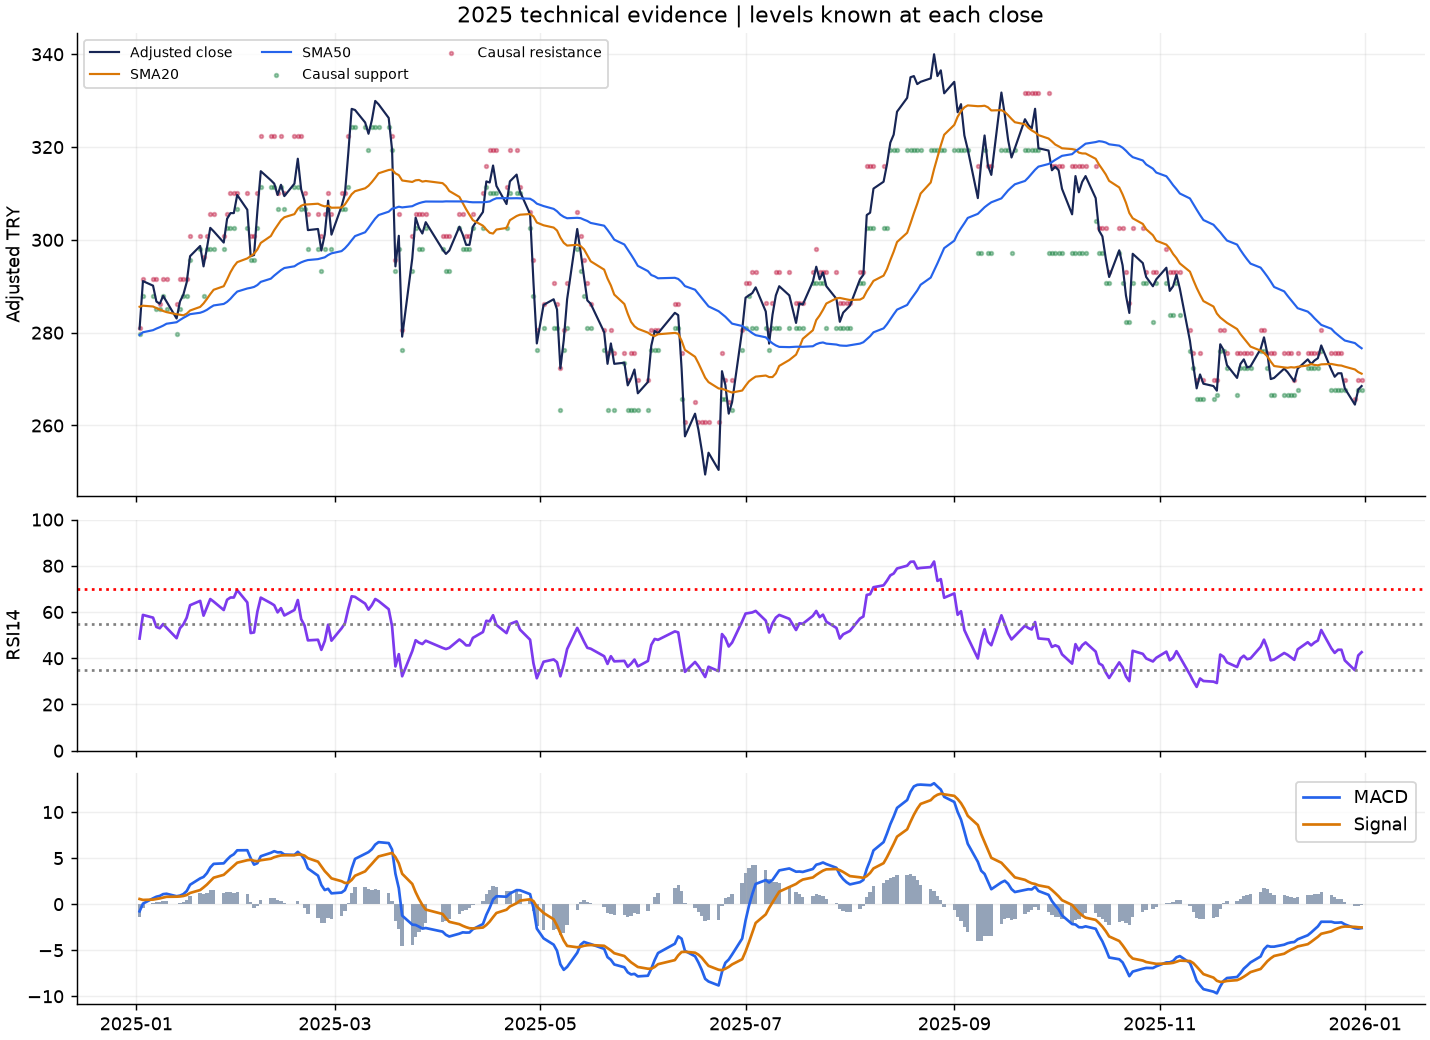

In [4]:
display(features[['close','sma_fast','sma_slow','ema_fast','rsi','macd','macd_signal','relative_volume','support','resistance']].tail())
display(Image(filename=str(OUT/'figures/technical.png')))

## 4. Financial alignment and explainable scoring

Backward joins use the first stock session after a verified or assumed release date. No initial backfill is used. The original-report archive preserves current and comparative columns as separately dated observations.

,financial_period,available_at,revenue,net_profit,ebitda,roe,net_debt_ebitda
0,2021-12-31,2022-03-02,9.737800e+10,8.213000e+09,2.792200e+10,0.126216,5.805064
1,2022-12-31,2023-03-02,3.111690e+11,4.742900e+10,7.868400e+10,0.348663,2.186048
2,2023-12-31,2024-04-04,5.043980e+11,1.630030e+11,1.153970e+11,0.510438,2.001976
3,2024-12-31,2025-03-03,7.454300e+11,1.133780e+11,1.362560e+11,0.199408,1.736907


date,2025-12-31
f_growth,1.00
f_profit_growth,0.00
f_roe,0.00
f_leverage,1.00
f_valuation,1.00
t_trend,0.00
t_rsi,1.00
t_macd,0.00
t_volume,0.00
t_support,1.00


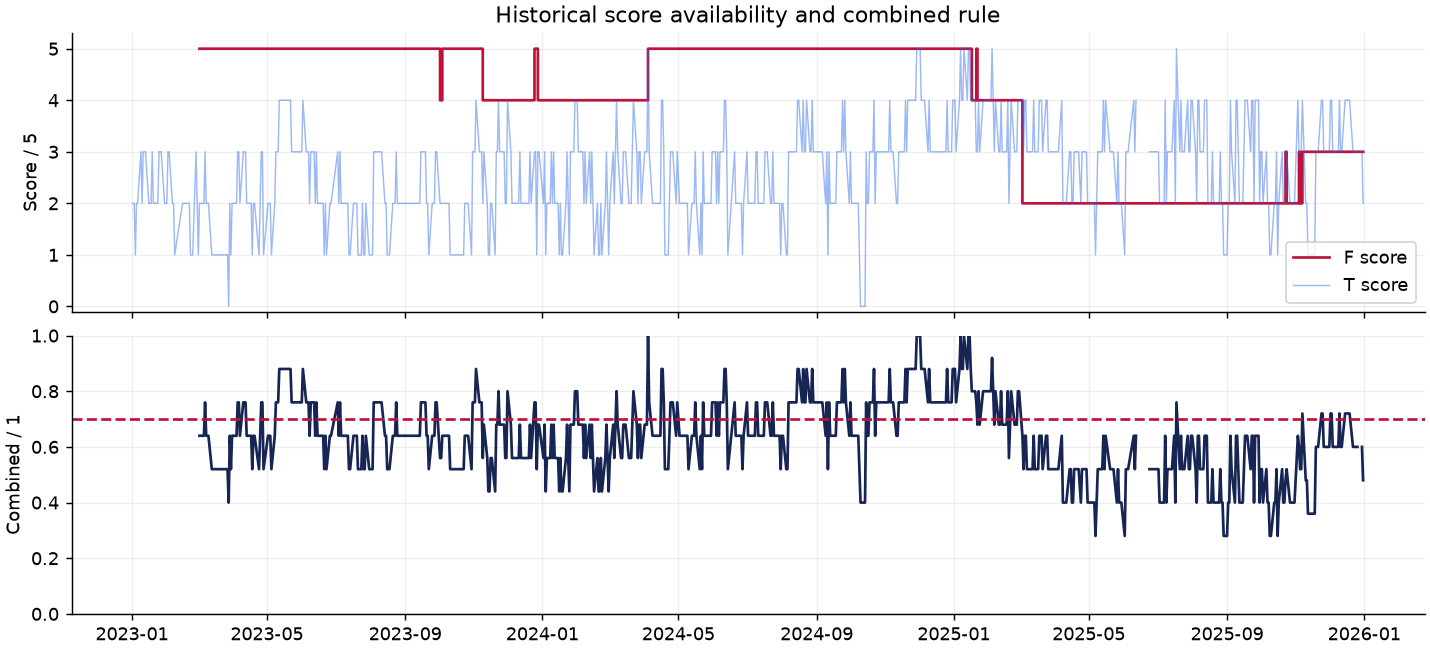

In [5]:
snapshots = pd.read_csv(OUT/'financial_snapshots.csv')
display(snapshots[['financial_period','available_at','revenue','net_profit','ebitda','roe','net_debt_ebitda']])
columns = [c for c in features if c.startswith(('t_','f_'))] + ['technical_score','fundamental_score','combined_score']
display(features[columns].tail(1).T)
display(Image(filename=str(OUT/'figures/scores.png')))

## 5. Decisions, next-open orders and costs

A close-triggered stop does not guarantee the stop price. The following order ledger shows actual simulated dates, fills, slippage and fees; no real order is sent.

In [6]:
orders = pd.read_csv(OUT/'combined_orders.csv', parse_dates=['decision_date','execution_date'])
assert (orders.execution_date > orders.decision_date).all()
display(orders.head(8))
display(pd.read_csv(OUT/'combined_trades.csv'))

,decision_date,execution_date,side,units,reference_price,fill_price,commission,slippage_cost,cash_after,reason
0,2023-05-10,2023-05-11,BUY,809.286737,123.380466,123.442156,99.900100,49.925087,0.000000e+00,combined_entry
1,2023-06-05,2023-06-06,SELL,809.286737,160.208998,160.128893,129.590190,64.827509,1.294606e+05,rsi_exit
2,2023-11-23,2023-11-24,BUY,506.994075,254.966756,255.094240,129.331268,64.633317,-1.455192e-11,combined_entry
3,2023-12-22,2023-12-25,SELL,506.994075,227.027886,226.914372,115.044242,57.550896,1.149292e+05,close_stop_loss
4,2023-12-26,2023-12-27,BUY,516.135657,222.338843,222.450013,114.814383,57.378502,-1.455192e-11,combined_entry
5,2024-01-04,2024-01-05,SELL,516.135657,228.395516,228.281319,117.824128,58.941535,1.177063e+05,trend_reversal
6,2024-01-30,2024-01-31,BUY,442.319996,265.712497,265.845353,117.588716,58.764975,-2.910383e-11,combined_entry
7,2024-01-31,2024-02-01,SELL,442.319996,266.689398,266.556053,117.903072,58.981027,1.177852e+05,rsi_exit


,entry_date,exit_date,entry_price,exit_price,units,net_pnl,net_return,holding_sessions,entry_reason,exit_reason,status
0,2023-05-11,2023-06-06,123.442156,160.128893,809.286737,29460.599326,0.294606,17,combined_entry,rsi_exit,closed
1,2023-11-24,2023-12-25,255.094240,226.914372,506.994075,-14531.401561,-0.112246,21,combined_entry,close_stop_loss,closed
2,2023-12-27,2024-01-05,222.450013,228.281319,516.135657,2777.106480,0.024164,6,combined_entry,trend_reversal,closed
3,2024-01-31,2024-02-01,265.845353,266.556053,442.319996,78.865049,0.000670,1,combined_entry,rsi_exit,closed
4,2024-03-08,2024-04-30,266.822740,317.328636,440.995028,22015.241114,0.186910,32,combined_entry,rsi_exit,closed
5,2024-06-10,2024-06-20,293.456142,307.808760,475.916942,6544.501806,0.046813,5,combined_entry,trend_reversal,closed
6,2024-11-22,2025-01-20,273.175674,297.800705,535.182037,12873.297907,0.087965,40,combined_entry,maximum_holding_period,closed
7,2025-01-22,2025-03-04,294.922201,306.832358,539.325796,6098.913222,0.038305,29,combined_entry,fundamental_deterioration,closed


## 6. Results and baselines

Returns are nominal TRY and cash earns zero. BIST100 is a price index with three missing comparison sessions; the adjusted stock series uses synthetic fractional units. Win rate only counts closed trades, so buy-and-hold has no closed-trade win rate.

,Strategy,Return,Max drawdown,Sharpe (rf=0),Closed trades,Win rate,Exposure,Sessions
0,combined,65.32%,-13.85%,1.08,8,87.50%,20.16%,749
1,technical,61.19%,-13.16%,1.00,11,63.64%,26.70%,749
2,buy_hold,92.73%,-25.61%,0.75,0,Unavailable,100.00%,749
3,bist100,102.24%,-22.86%,0.97,—,Unavailable,Unavailable,746


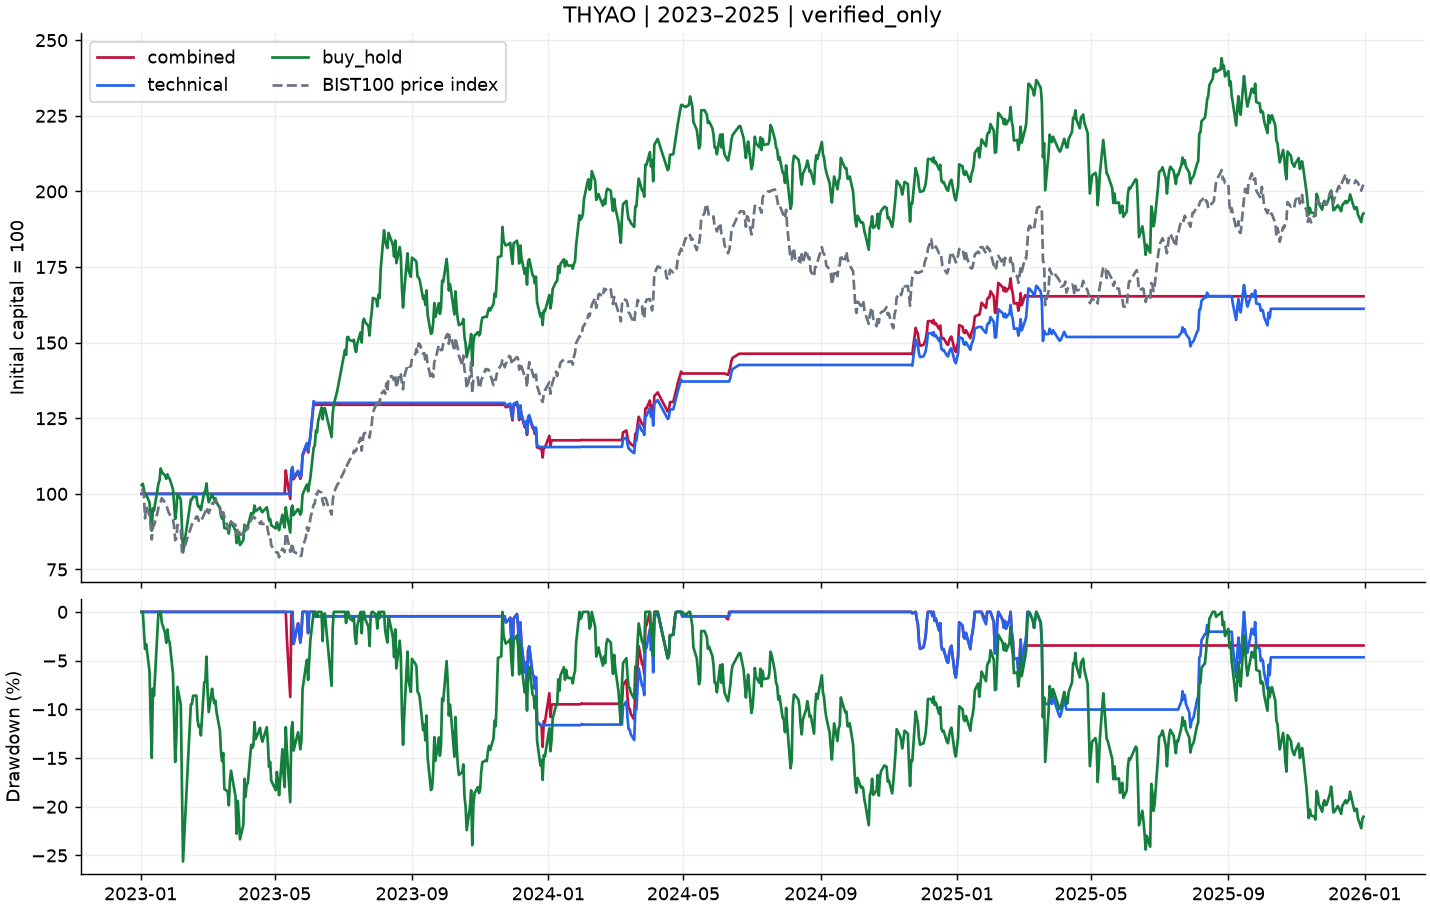

,bist100,buy_hold,combined,technical
2023,0.341534,0.602932,0.152612,0.154778
2024,0.303395,0.201623,0.248105,0.239847
2025,0.142360,-0.027665,0.082610,0.064260


In [7]:
display(pd.read_csv(OUT/'performance_table.csv'))
display(Image(filename=str(OUT/'figures/performance.png')))
annual = json.loads((OUT/'annual_evaluations.json').read_text())
display(pd.DataFrame({year:{mode:m['cumulative_return'] for mode,m in data.items()} for year,data in annual.items()}).T)

## 7. Predeclared sensitivity and strict source mode

2023–2024 variants do not select a winner on the 2025 holdout. A zero-cost rerun can change stop timing; the separate gross counterfactual keeps execution dates fixed. Strict source mode now admits the 136 reviewed original-report observations. The earlier USD table study remains separately qualified.

In [8]:
from scripts.sensitivity import main as run_sensitivity
run_sensitivity()
display(pd.read_csv(OUT/'sensitivity.csv')[['variant','cumulative_return','maximum_drawdown','closed_trades']])
from bist_analytics.analysis.fundamentals import get_fundamental_metrics
strict = get_fundamental_metrics(records, '2025-12-31', currency=cfg.fundamental_currency)
assert strict['revenue'] == 745430000000
print('Strict source result:', strict['financial_status'])

         variant  cumulative_return  maximum_drawdown  closed_trades
        baseline           0.469099         -0.138531              6
      zero_costs           0.498026         -0.134022              6
commission_20bps           0.450126         -0.141970              6
       entry_065           0.550936         -0.097205              6
       entry_075           0.469099         -0.138531              6
   debt_limit_2x           0.431747         -0.131559              5


,variant,cumulative_return,maximum_drawdown,closed_trades
0,baseline,0.469099,-0.138531,6
1,zero_costs,0.498026,-0.134022,6
2,commission_20bps,0.450126,-0.141970,6
3,entry_065,0.550936,-0.097205,6
4,entry_075,0.469099,-0.138531,6
5,debt_limit_2x,0.431747,-0.131559,5


Strict source result: available


## 8. Genuine MCP AI evidence

The following trace was produced by an actual authenticated LLM host, not a mocked conversation. Re-reading it is offline. A fresh model run is optional because it consumes model usage.

In [9]:
trace = ROOT/'outputs/agent/analysis_demo.jsonl'
events = [json.loads(line) for line in trace.read_text(encoding='utf-8').splitlines()]
calls = [e['item'] for e in events if e.get('type')=='item.completed' and e.get('item',{}).get('type')=='mcp_tool_call']
display(pd.DataFrame([{'tool':c['tool'],'status':c['status'],'error':c.get('error')} for c in calls]))
print((ROOT/'outputs/agent/analysis_demo.md').read_text(encoding='utf-8'))

,tool,status,error
0,generate_report,completed,None
1,calculate_scores,completed,None
2,find_support_resistance,completed,None
3,calculate_indicators,completed,None
4,get_fundamental_metrics,completed,None
5,generate_signal,completed,None
6,run_backtest,completed,None
7,get_stock_history,completed,None


## THYAO.IS — as of 2025-12-31

**Rule signal: HOLD with `holding=false`**, meaning remain out of the position. `generate_signal` identifies the blocking reason as `trend_filter`; this is an academic rule output, not an executed order.

### Evidence

- **Technical:** Actual market date is **2025-12-31**. Adjusted and raw close were **TRY 268.50**, below fast/slow SMAs of **271.1625 / 276.64**. RSI was **42.6210**, MACD histogram **−0.0781**, and relative volume **0.6947**, consistent with weak trend and momentum. Support/resistance were **TRY 267.75 / 269.8642**, with `in_zone=false`; pivots require five subsequent sessions for confirmation before use. Sources: `get_stock_history`, `calculate_indicators`, `find_support_resistance`.
- **Fundamental:** The active annual financial period is **2024-12-31**, available from **2025-03-03**, aged **303 days**. Revenue growth was **0.477861**, net-profit growth **−0.304442**, ROE **0.199408**, net-debt/EBITDA **1.736907**, and P/E **3.268094**.

## 9. Interpretation and acceptance boundary

The combined rule exceeded technical-only endpoint return but underperformed stock buy-and-hold and BIST100. Eight closed trades are weak evidence for generalization. Annual updates, nominal currency translation, one selected stock, inflation, simplistic execution and benchmark differences limit the conclusions. The source correction followed inspection of the earlier USD run, so the chronological holdout is not a pristine blind test. See the report, source manifest and acceptance audit; presentation preparation follows implementation.